<div style=" background-color: RGB(0,114,200);" >
<h1 style="margin: auto; padding: 20px 0; color:#fff; text-align: center">PROJET 5 DATA ANALYST</h1>
<h2 style="margin: auto; padding: 20px 0; color:#fff; text-align: center">Optimisez la gestion d'une boutique avec R ou Python
</h2>
</div>

Aujourd’hui est un grand jour, je commence une mission en tant que data analyst freelance chez BottleNeck, un marchand de vin très prestigieux. Mon manager sur cette mission (Laurent) m'accueille chaleureusement et me propose de partager un petit café avec le reste de l’équipe du service Numérique. L’ambiance est bonne, et me voilà déjà parfaitement intégré dans cette équipe détendue mais professionnelle.
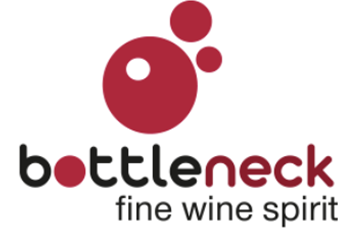

# Missions :

+ Rapprocher les deux exports : un export de l’ERP contenant les références produit, leur prix de vente et leur état de stock, et un export d’une table de l’outil de CMS contenant les informations des produits commercialisés en ligne (nom, description, nombre de ventes...).

+ Suivre le chiffre d’affaires par produit, ainsi que le total du chiffre d’affaires réalisé en ligne.

+ Effectuer une analyse sur le prix des produits afin de détecter d’éventuelles valeurs aberrantes, de les lister et d’en faire une représentation graphique pour plus de lisibilité.

<div style="background-color: RGB(0,150,250);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Etape 1 - Importation des librairies et chargement des fichiers</h2>
</div>

<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">1.1 - Importation des librairies</h3>
</div>

In [1]:
# Importation de la librairie Pandas pour la manipulation des dataframes
import pandas as pd
# Importation de la librairie Matplotlib pour la conception des graphiques
import matplotlib.pyplot as plt

# Pour éviter le warning lors de l'import des fichiers excel
import warnings
warnings.filterwarnings('ignore')

<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">1.2 - Chargement des fichiers Excel</h3>
</div>

In [2]:
# Importation du fichier export ERP
erp = pd.read_excel('data/Fichier_erp.xlsx')

# Importation du fichier export WEB
web = pd.read_excel('data/Fichier_web.xlsx')

# Importation du fichier Liaison
liaison = pd.read_excel('data/Fichier_liaison.xlsx')

<div style="background-color: RGB(0,150,250);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Etape 2 - Analyse exploratoire et nettoyage des fichiers</h2>
</div>

<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">2.1 - Analyse exploratoire et nettoyage du fichier ERP</h3>
</div>

In [3]:
# Consulter le nombre de colonnes
# La nature des données dans chacune des colonnes
# Le nombre de valeurs présentes dans chacune des colonnes
erp.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 825 entries, 0 to 824
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   product_id      825 non-null    int64  
 1   onsale_web      825 non-null    int64  
 2   price           825 non-null    float64
 3   stock_quantity  825 non-null    int64  
 4   stock_status    825 non-null    object 
dtypes: float64(1), int64(3), object(1)
memory usage: 32.4+ KB


In [4]:
# Le tableau ne comporte pas des valeurs manquantes
# Affichage des 10 premières lignes
erp.head(10)

,product_id,onsale_web,price,stock_quantity,stock_status
0,3847,1,24.2,0,outofstock
1,3849,1,34.3,0,outofstock
2,3850,1,20.8,0,outofstock
3,4032,1,14.1,0,outofstock
4,4039,1,46.0,0,outofstock
5,4040,1,34.3,0,outofstock
6,4041,1,32.7,15,instock
7,4042,1,31.2,34,instock
8,4043,1,60.0,12,instock
9,4045,1,42.6,66,instock


In [5]:
# Affichage des différentes valeurs de la colonne "stock_status" + leur occurence (données qualitatives)
erp['stock_status'].value_counts()

stock_status
instock       638
outofstock    187
Name: count, dtype: int64

In [6]:
# Affichage des produits qui ont un stock > 0 mais "outofstock"
erp[(erp['stock_quantity'] > 0) & (erp['stock_status'] == "outofstock") ]

,product_id,onsale_web,price,stock_quantity,stock_status
19,4055,0,86.1,1,outofstock
49,4090,0,73.0,6,outofstock
50,4092,0,47.0,6,outofstock
630,5826,1,41.2,12,outofstock
696,6125,0,14.2,48,outofstock


Il y a 5 produits qui ont un stock positif mais qui sont identifiés comme "stock_status = outofstock".
En entreprise, ce cas est à remonter au responsable du système d'information car c'est une incohérence.

In [7]:
# Affichage des produits qui ont un stock <= 0 mais "instock"
erp[(erp['stock_quantity'] <= 0) & (erp['stock_status'] == "instock") ]

,product_id,onsale_web,price,stock_quantity,stock_status
443,4954,1,25.0,0,instock


Il y a 1 produit qui a un stock nul mais qui est identifié comme "stock_status = instock".
En entreprise, ce cas est à remonter au responsable du système d'information car c'est une incohérence.

La clé primaire de la table ERP est : "product_id"

In [8]:
# Vérification des doublons
print("Le tableau 'erp' comporte {} doublon(s)".format(erp.duplicated().sum()))

Le tableau 'erp' comporte 0 doublon(s)


La clé primaire "product_id" est unique car elle ne comporte pas de doublon => UNICITE = OK

In [9]:
# Affichage des informations sur les colonnes numériques
erp.describe()

,product_id,onsale_web,price,stock_quantity
count,825.000000,825.000000,825.000000,825.000000
mean,5162.597576,0.869091,32.384000,26.583030
std,902.644635,0.337506,26.832271,45.875948
min,3847.000000,0.000000,-8.000000,-1.000000
25%,4348.000000,1.000000,14.600000,1.000000
50%,4907.000000,1.000000,24.400000,11.000000
75%,5805.000000,1.000000,42.000000,34.000000
max,7338.000000,1.000000,225.000000,578.000000


+ Il y a des produits avec prix négatif.
+ Il y a des produits avec une quantité de stock négative.
+ Dans la colonne stock, on reparque que la valeur max est très élevée par rapport à la moyenne. 

In [10]:
# Affichage des produits avec prix négatif
erp[erp['price'] < 0]

,product_id,onsale_web,price,stock_quantity,stock_status
469,5017,0,-8.0,0,outofstock
739,6594,0,-1.0,192,instock


In [11]:
# Affichage des produits à stock négatif
erp[erp['stock_quantity'] < 0]

,product_id,onsale_web,price,stock_quantity,stock_status
449,4973,0,10.0,-1,outofstock
573,5700,1,44.5,-1,outofstock


In [12]:
# Affichage de la valeur max des stock : 578.
erp[erp["stock_quantity"] == erp["stock_quantity"].max()]

,product_id,onsale_web,price,stock_quantity,stock_status
130,4208,1,7.6,578,instock


<Axes: xlabel='product_id'>

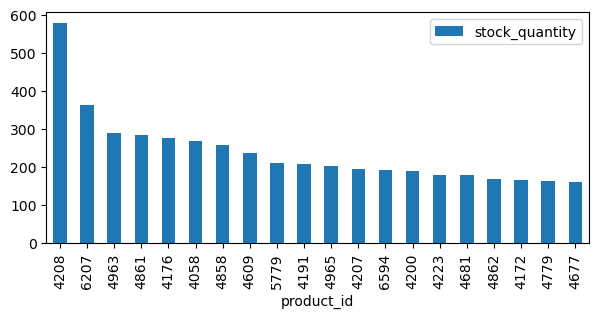

In [13]:
# Affichage des TOP20 quantité de stock 
top_stock = erp.sort_values("stock_quantity", ascending=False)
top_stock = top_stock.head(20)
top_stock.plot(kind="bar", x="product_id", y="stock_quantity",figsize=(7,3))

<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">2.2 - Analyse exploratoire et nettoyage du fichier WEB</h3>
</div>

In [14]:
# Consulter le nombre de colonnes
# La nature des données dans chacune des colonnes
# Le nombre de valeurs présentes dans chacune des colonnes
web.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1513 entries, 0 to 1512
Data columns (total 28 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   sku                    1428 non-null   object        
 1   virtual                1513 non-null   int64         
 2   downloadable           1513 non-null   int64         
 3   rating_count           1513 non-null   int64         
 4   average_rating         1430 non-null   float64       
 5   total_sales            1430 non-null   float64       
 6   tax_status             716 non-null    object        
 7   tax_class              0 non-null      float64       
 8   post_author            1430 non-null   float64       
 9   post_date              1430 non-null   datetime64[ns]
 10  post_date_gmt          1430 non-null   datetime64[ns]
 11  post_content           0 non-null      float64       
 12  post_title             1430 non-null   object        
 13  pos

In [15]:
# Affichage des 10 premières lignes
web.head(10)

,sku,virtual,downloadable,rating_count,average_rating,total_sales,tax_status,tax_class,post_author,post_date,...,post_name,post_modified,post_modified_gmt,post_content_filtered,post_parent,guid,menu_order,post_type,post_mime_type,comment_count
0,16004,0,0,0,0.0,5.0,NaN,NaN,2.0,2018-06-07 16:27:25,...,chateau-du-couvent-pomerol-2017,2020-08-25 18:35:02,2020-08-25 16:35:02,NaN,0.0,https://www.bottle-neck.fr/wp-content/uploads/...,0.0,attachment,image/jpeg,0.0
1,NaN,0,0,0,NaN,NaN,NaN,NaN,NaN,NaT,...,NaN,NaT,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,15075,0,0,0,0.0,3.0,taxable,NaN,2.0,2018-02-14 15:39:43,...,pares-balta-penedes-indigena-2017,2020-08-20 15:35:02,2020-08-20 13:35:02,NaN,0.0,https://www.bottle-neck.fr/?post_type=product&...,0.0,product,NaN,0.0
3,16209,0,0,0,0.0,6.0,taxable,NaN,2.0,2018-02-14 17:15:31,...,maurel-cabardes-tradition-2017,2020-08-05 18:05:03,2020-08-05 16:05:03,NaN,0.0,https://www.bottle-neck.fr/?post_type=product&...,0.0,product,NaN,0.0
4,15763,0,0,0,0.0,1.0,NaN,NaN,2.0,2020-01-25 14:08:16,...,domaine-de-la-monardiere-vacqueyras-les-vieill...,2020-08-21 11:35:02,2020-08-21 09:35:02,NaN,0.0,https://www.bottle-neck.fr/wp-content/uploads/...,0.0,attachment,image/jpeg,0.0
5,13895,0,0,0,0.0,0.0,taxable,NaN,2.0,2019-03-19 10:41:50,...,chateau-saransot-dupre-bordeaux-blanc-2016,2020-04-25 21:11:40,2020-04-25 19:11:40,NaN,0.0,https://www.bottle-neck.fr/?post_type=product&...,0.0,product,NaN,0.0
6,12857,0,0,0,0.0,0.0,taxable,NaN,2.0,2018-04-12 17:56:13,...,chateau-de-puligny-montrachet-1cru-champ-canet...,2020-02-06 16:35:02,2020-02-06 15:35:02,NaN,0.0,https://www.bottle-neck.fr/?post_type=product&...,0.0,product,NaN,0.0
7,15740,0,0,0,0.0,0.0,NaN,NaN,2.0,2020-04-25 12:32:17,...,jean-faure-saint-emilion-grand-cru-2015,2020-08-27 11:35:02,2020-08-27 09:35:02,NaN,0.0,https://www.bottle-neck.fr/wp-content/uploads/...,0.0,attachment,image/jpeg,0.0
8,14253,0,0,0,0.0,0.0,NaN,NaN,2.0,2018-02-20 15:29:32,...,domaine-huet-vouvray-haut-lieu-sec-2016,2020-07-22 09:55:01,2020-07-22 07:55:01,NaN,0.0,https://www.bottle-neck.fr/wp-content/uploads/...,0.0,attachment,image/jpeg,0.0
9,14106,0,0,0,0.0,0.0,taxable,NaN,2.0,2019-06-08 09:54:21,...,stephane-tissot-chateau-chalon-2011,2020-05-29 17:35:03,2020-05-29 15:35:03,NaN,0.0,https://www.bottle-neck.fr/?post_type=product&...,0.0,product,NaN,0.0


In [16]:
# Création d'une table avec les variables nécessaire pour la suite de l'exercice
web_subset = web[["sku","total_sales","post_date_gmt","post_title","post_type"]]
web_subset.head(10)

,sku,total_sales,post_date_gmt,post_title,post_type
0,16004,5.0,2018-06-07 14:27:25,Château du Couvent Pomerol 2017,attachment
1,NaN,NaN,NaT,NaN,NaN
2,15075,3.0,2018-02-14 14:39:43,Parés Baltà Penedès Indigena 2017,product
3,16209,6.0,2018-02-14 16:15:31,Maurel Cabardès Tradition 2017,product
4,15763,1.0,2020-01-25 13:08:16,Domaine de la Monardière Vacqueyras Vieilles V...,attachment
5,13895,0.0,2019-03-19 09:41:50,Château Saransot-Dupré Bordeaux Blanc 2016,product
6,12857,0.0,2018-04-12 15:56:13,Château de Meursault Puligny-Montrachet 1er Cr...,product
7,15740,0.0,2020-04-25 10:32:17,Château Jean Faure Saint-Emilion Grand Cru 2015,attachment
8,14253,0.0,2018-02-20 14:29:32,Domaine Huet Vouvray Haut-Lieu Sec 2017,attachment
9,14106,0.0,2019-06-08 07:54:21,Stéphane Tissot Château-Chalon 2011,product


La clé primaire de la table Web est "sku"

In [17]:
# Vérification des doublons
print("Le tableau 'web_subset' comporte {} doublon(s)".format(web_subset.duplicated().sum()))

Le tableau 'web_subset' comporte 82 doublon(s)


In [18]:
# Affichage des informations sur les colonnes numériques
web_subset.describe()

,total_sales,post_date_gmt
count,1430.000000,1430
mean,3.855245,2018-08-22 01:53:30.097902080
min,0.000000,2018-02-08 11:58:52
25%,0.000000,2018-02-27 19:01:12.500000
50%,1.000000,2018-04-19 12:56:05
75%,4.000000,2019-01-31 13:35:47
max,96.000000,2020-07-20 09:00:00
std,7.702346,NaN


In [19]:
# Affichage du nombre de cellule vide
web_subset.isna().sum()

sku              85
total_sales      83
post_date_gmt    83
post_title       83
post_type        83
dtype: int64

85 lignes n'ont pas de sku renseigné

In [20]:
# Création et affichage d'un tableau avec sku = vide
web_empty = web_subset.loc[web_subset["sku"].isna()]
web_empty

,sku,total_sales,post_date_gmt,post_title,post_type
1,NaN,NaN,NaT,NaN,NaN
17,NaN,NaN,NaT,NaN,NaN
82,NaN,NaN,NaT,NaN,NaN
97,NaN,NaN,NaT,NaN,NaN
121,NaN,NaN,NaT,NaN,NaN
...,...,...,...,...,...
1378,NaN,NaN,NaT,NaN,NaN
1421,NaN,NaN,NaT,NaN,NaN
1448,NaN,NaN,NaT,NaN,NaN
1450,NaN,NaN,NaT,NaN,NaN


In [21]:
# Affichage des lignes dont le "sku" est vide mais pas le reste des données
web_subset[web_subset["sku"].isna() & ~web_subset["total_sales"].isna()]

,sku,total_sales,post_date_gmt,post_title,post_type
353,NaN,3.0,2018-08-08 09:23:43,Pierre Jean Villa Condrieu Jardin Suspendu 2018,product
488,NaN,10.0,2018-07-31 10:07:23,Pierre Jean Villa Côte Rôtie Fongeant 2017,product


Il est probable que les produits suivants n'est pas reconnu de la base de données produits web pourtant ils sont en vente sur le site. En entreprise, on devrait se rapprocher du responsable métier pour savoir la raison pour laquelle cela s'est produit afin d'améliorer la qualité de données.

Il n'est pas possible de retrouver le "sku" avec les données que nous avons. Les données seront donc retirées.

In [22]:
# Création d'une table avec sku renseigné
web_subset = web_subset[~web_subset["sku"].isna()]
web_subset

,sku,total_sales,post_date_gmt,post_title,post_type
0,16004,5.0,2018-06-07 14:27:25,Château du Couvent Pomerol 2017,attachment
2,15075,3.0,2018-02-14 14:39:43,Parés Baltà Penedès Indigena 2017,product
3,16209,6.0,2018-02-14 16:15:31,Maurel Cabardès Tradition 2017,product
4,15763,1.0,2020-01-25 13:08:16,Domaine de la Monardière Vacqueyras Vieilles V...,attachment
5,13895,0.0,2019-03-19 09:41:50,Château Saransot-Dupré Bordeaux Blanc 2016,product
...,...,...,...,...,...
1508,12881,2.0,2019-03-28 14:25:14,Domaine de Montbourgeau L'Etoile Vin Jaune 2009,attachment
1509,15663,3.0,2018-02-27 09:27:01,Chermette Domaine du Vissoux Brouilly Pierreux...,product
1510,15910,0.0,2019-03-28 09:59:43,Thevenet Quintaine Viré-Clessé La Bongran 2015,product
1511,38,38.0,2018-04-18 10:25:58,Emile Boeckel Crémant Brut Blanc de Blancs,attachment


In [23]:
# Vérification s'il reste des valeurs vides
web_subset.isna().sum()

sku              0
total_sales      0
post_date_gmt    0
post_title       0
post_type        0
dtype: int64

Il n'y a plus de valeurs vides

In [24]:
# Revérification des doublons
print("Le tableau 'web_subset' comporte {} doublon(s)".format(web_subset["sku"].duplicated().sum()))

Le tableau 'web_subset' comporte 714 doublon(s)


In [25]:
# Affichage des différentes valeurs de la colonne "post_type" + leur occurence (données qualitatives)
web_subset['post_type'].value_counts()

post_type
attachment    714
product       714
Name: count, dtype: int64

Pour la suite des requêtes, nous allons nous intéresser sur les données de type "product" et supprimer les doublons

In [26]:
# Avant suppression des doublons, vérifions s'il existe une différence entre les doublons pour le cas des sku suivants : 16004 et 15075
web_subset.loc[(web_subset["sku"] == 16004) | (web_subset["sku"] == 15075)]


,sku,total_sales,post_date_gmt,post_title,post_type
0,16004,5.0,2018-06-07 14:27:25,Château du Couvent Pomerol 2017,attachment
2,15075,3.0,2018-02-14 14:39:43,Parés Baltà Penedès Indigena 2017,product
581,16004,5.0,2018-06-07 14:27:25,Château du Couvent Pomerol 2017,product
1432,15075,3.0,2018-02-14 14:39:43,Parés Baltà Penedès Indigena 2017,attachment


La différence entre les lignes de même sku se situe au niveau de la colonne "post_type"

In [27]:
# Supprimons donc les lignes de la colonne "post_type = attachment" pour supprimer les doublons
web_subset = web_subset.loc[web_subset["post_type"]=="product"]
web_subset

,sku,total_sales,post_date_gmt,post_title,post_type
2,15075,3.0,2018-02-14 14:39:43,Parés Baltà Penedès Indigena 2017,product
3,16209,6.0,2018-02-14 16:15:31,Maurel Cabardès Tradition 2017,product
5,13895,0.0,2019-03-19 09:41:50,Château Saransot-Dupré Bordeaux Blanc 2016,product
6,12857,0.0,2018-04-12 15:56:13,Château de Meursault Puligny-Montrachet 1er Cr...,product
9,14106,0.0,2019-06-08 07:54:21,Stéphane Tissot Château-Chalon 2011,product
...,...,...,...,...,...
1501,15941,4.0,2018-02-12 13:26:52,Domaine de la Jérôme Côtes du Rhône Village 201,product
1503,10459,0.0,2018-04-13 13:58:19,Alphonse Mellot Sancerre Rouge Génération XIX ...,product
1507,16320,3.0,2018-02-12 11:49:29,Mourgues du Grès IGP Pont du Gard Terre d'Arge...,product
1509,15663,3.0,2018-02-27 09:27:01,Chermette Domaine du Vissoux Brouilly Pierreux...,product


In [28]:
# Vérification finale des doublons
print("Le tableau 'web_subset' comporte {} doublon(s)".format(web_subset["sku"].duplicated().sum()))

Le tableau 'web_subset' comporte 0 doublon(s)


La clé primaire "sku" est unique car elle ne comporte pas de doublon => UNICITE = OK

<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">2.3 - Analyse exploratoire et nettoyage du fichier Liaison</h3>
</div>

In [29]:
# Consulter le nombre de colonnes
# La nature des données dans chacune des colonnes
# Le nombre de valeurs présentes dans chacune des colonnes
liaison.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 825 entries, 0 to 824
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   product_id  825 non-null    int64 
 1   id_web      734 non-null    object
dtypes: int64(1), object(1)
memory usage: 13.0+ KB


In [30]:
# Affichage des 10 premières lignes
liaison.head(10)

,product_id,id_web
0,3847,15298
1,3849,15296
2,3850,15300
3,4032,19814
4,4039,19815
5,4040,15303
6,4041,14975
7,4042,16042
8,4043,14980
9,4045,16041


In [31]:
# Vérification des doublons
print("Le tableau 'liaison' comporte {} doublon(s)".format(liaison.duplicated().sum()))

Le tableau 'liaison' comporte 0 doublon(s)


La clé primaire "product_id" est unique car elle ne comporte pas de doublon => UNICITE = OK

In [32]:
# Affichage du nombre de cellule vide
liaison.isna().sum()

product_id     0
id_web        91
dtype: int64

Il y a 91 produits qui n'ont pas de "id_web" référencé. 
Il se peut que ces produits ne sont pas en vente sur internet mais seulement en magasin physique

In [33]:
# Suppression des "id_web" vide
liaison = liaison.loc[~liaison["id_web"].isna()]

In [34]:
# Remplacement du nom de la colone "id_web" par "sku"
liaison = liaison.rename(columns={"id_web" : "sku"})
liaison.head(10)

,product_id,sku
0,3847,15298
1,3849,15296
2,3850,15300
3,4032,19814
4,4039,19815
5,4040,15303
6,4041,14975
7,4042,16042
8,4043,14980
9,4045,16041


<div style="background-color: RGB(0,150,250);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Etape 3 - Analyses Chiffre d'Affaires</h2>
</div>

# Jointures
Inner join pour vérifier la correspondance entre les 3 fichiers ERP, WEB et LIAISON (vérifier si il y a des produits qui ne sont pas référenciés) : 
- df_web = Inner join entre web_subset et liaison
- df_erp = Inner join entre liaison et erp
- df_final = Jointures des 2 fichiers => filrer sur les lignes communes (_merge = both)

In [35]:
# Jointure entre web_subset et liaison
df_web = pd.merge(web_subset, liaison, indicator= True, on='sku', how='outer')

In [36]:
# Affichage des détails de _merge df_web
df_web['_merge'].value_counts()

_merge
both          714
right_only     20
left_only       0
Name: count, dtype: int64

Analyse de la désynchronisation entre les fichiers Web et Liaison
+ 714 produits communes entre les 2 fichiers
+ 20 produits qui sont référenciés dans le fichier Liaison mais n'apparaissent pas dans le fichier web

In [37]:
# Affichage des 20 produits qui sont en désynchronisation
df_web[df_web['_merge'] == "right_only"]

,sku,total_sales,post_date_gmt,post_title,post_type,product_id,_merge
714,13771,NaN,NaT,NaN,NaN,4289,right_only
715,15065,NaN,NaT,NaN,NaN,4568,right_only
716,14785,NaN,NaT,NaN,NaN,4584,right_only
717,12601,NaN,NaT,NaN,NaN,4741,right_only
718,15154,NaN,NaT,NaN,NaN,4864,right_only
719,14360,NaN,NaT,NaN,NaN,4869,right_only
720,15608,NaN,NaT,NaN,NaN,4921,right_only
721,15586,NaN,NaT,NaN,NaN,4922,right_only
722,15272,NaN,NaT,NaN,NaN,5018,right_only
723,15630,NaN,NaT,NaN,NaN,5021,right_only


In [38]:
# Jointure entre liaison et erp
df_erp = pd.merge(liaison,erp, indicator= True, on='product_id', how='outer')

In [39]:
# Affichage des détails de _merge df_web
df_erp['_merge'].value_counts()

_merge
both          734
right_only     91
left_only       0
Name: count, dtype: int64

Analyse de la désynchronisation entre les fichiers ERP et Liaison
+ 734 produits communes entre les 2 fichiers
+ 91 produits qui sont référenciés dans le fichier ERP mais n'apparaissent pas dans le fichier Liaison

In [40]:
# Affichage des 91 produits qui sont en désynchronisation
df_erp[df_erp['_merge'] == "right_only"]

,product_id,sku,onsale_web,price,stock_quantity,stock_status,_merge
734,4055,NaN,0,86.1,1,outofstock,right_only
735,4090,NaN,0,73.0,6,outofstock,right_only
736,4092,NaN,0,47.0,6,outofstock,right_only
737,4195,NaN,0,14.1,0,outofstock,right_only
738,4209,NaN,0,73.5,0,outofstock,right_only
...,...,...,...,...,...,...,...
820,7196,NaN,0,31.0,55,instock,right_only
821,7200,NaN,0,31.0,6,instock,right_only
822,7201,NaN,0,31.0,18,instock,right_only
823,7203,NaN,0,45.0,30,instock,right_only


In [41]:
# Constitution de la df_final en faisant le rapprochement entre les 2 fichiers Web et ERP en prenant les lignes = "both"
# Web + Liaison
df_final = pd.merge(web_subset,liaison, on='sku', how='outer')

# Web + Liaison + ERP
df_final = pd.merge(df_final,erp, indicator= True,on='product_id', how='outer')

# Filtrer sur _merge = "both" pour avoir les données qui appartiennet aux 2 dataframes
df_final = df_final[df_final['_merge'] == "both"]

# Supprimer la colonne "_merge" car ce n'est plus nécessaire pour la suite de l'analyse
df_final = df_final.drop(['_merge'], axis=1)

Désynchronisation entre le système ERP et WEB
=> automatiser nettoyage de données pour économiser du temps

In [42]:
# Affichage des 10 premières lignes
df_final.head(10)

,sku,total_sales,post_date_gmt,post_title,post_type,product_id,onsale_web,price,stock_quantity,stock_status
0,15075,3.0,2018-02-14 14:39:43,Parés Baltà Penedès Indigena 2017,product,4165,1,12.0,57,instock
1,16209,6.0,2018-02-14 16:15:31,Maurel Cabardès Tradition 2017,product,4174,1,5.7,94,instock
2,13895,0.0,2019-03-19 09:41:50,Château Saransot-Dupré Bordeaux Blanc 2016,product,5796,1,12.5,12,instock
3,12857,0.0,2018-04-12 15:56:13,Château de Meursault Puligny-Montrachet 1er Cr...,product,4582,1,109.6,7,instock
4,14106,0.0,2019-06-08 07:54:21,Stéphane Tissot Château-Chalon 2011,product,6106,1,74.8,15,instock
5,13996,2.0,2019-07-25 07:09:17,Domaine des Comtes Lafon Volnay 1er Cru Santen...,product,6212,1,115.0,2,instock
6,15428,7.0,2018-02-20 09:40:13,Domaine Saint-Denis Mâcon Lugny 2017,product,4246,1,15.3,25,instock
7,7033,4.0,2019-03-13 12:44:44,Huile d'Olive Extra Vierge Planeta Selezione C...,product,5756,1,42.2,30,instock
8,16077,37.0,2019-07-24 07:33:52,Domaine Giudicelli Patrimonio Rouge 2016,product,6207,1,25.2,363,instock
9,16237,36.0,2018-02-13 13:13:53,Elian Daros Côtes du Marmandais Clos Baquey 2015,product,4153,1,29.0,0,outofstock


In [43]:
# Création d'une colonne pour calculer le CA (Chiffre d'affaires)
df_final['CA'] = df_final['total_sales'] * df_final['price']

In [44]:
# Calcul et affichage du CA par produit
CA_produit = df_final.groupby('post_title')[['CA']].sum().reset_index()
CA_produit = CA_produit.sort_values(by='CA', ascending=False)
CA_produit

,post_title,CA
94,Champagne Gosset Grand Blanc de Blancs,4704.0
96,Champagne Gosset Grand Rosé,4263.0
200,Cognac Frapin VIP XO,2288.0
95,Champagne Gosset Grand Millésime 2006,1590.0
97,Champagne Gosset Grande Réserve,1560.0
...,...,...
354,Domaine de Vaccelli AOP Ajaccio Rouge Granit 1...,0.0
353,Domaine de Montgilet Vin de France Grolleau 2019,0.0
352,Domaine de Montgilet Coteaux de l'Aubance Les ...,0.0
348,Domaine de Montgilet Anjou Blanc 2016,0.0


<Figure size 700x500 with 0 Axes>

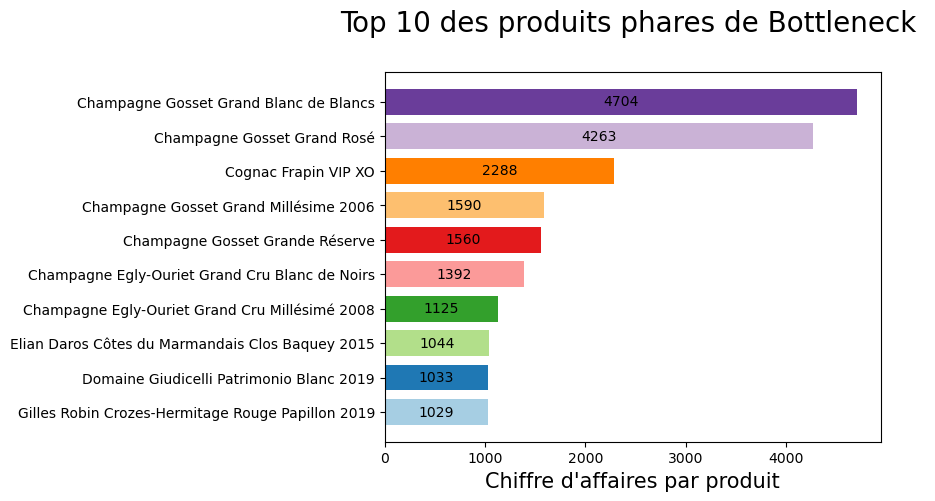

In [45]:
# Affichage du TOP 10 produits
# Récupérer les données à afficher dans barh
CA_produit = CA_produit.head(10)
CA_produit = CA_produit.sort_values(by='CA', ascending = True)
produit = CA_produit['post_title'].values
CA = CA_produit['CA'].values

# Ajuster la taille de l'image et obtenir la réf de couleur à utiliser
plt.figure(figsize=[7,5])
col_map = plt.get_cmap('Paired')

# Création du graphique avec titre,légende des axes et étiquettes des données
fig, ax = plt.subplots()
hbars = plt.barh(produit,CA , height=0.75, color=col_map.colors)
ax.set_xlabel("Chiffre d'affaires par produit", fontsize=15)
ax.set_title("Top 10 des produits phares de Bottleneck \n", fontsize=20)
ax.bar_label(hbars, fmt='%.0f', label_type='center')

# Affichage du graph
plt.show()

In [46]:
# Affichage du CA total
print('CA Total = {:.0f} €'.format(df_final['CA'].sum()))

CA Total = 70569 €


<div style="background-color: RGB(0,150,250);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Etape 4 - Analyse sur les prix des produits</h2>
</div>

Analyse sur le prix des produits afin de détecter d’éventuelles valeurs aberrantes, de les lister et d’en faire une représentation graphique


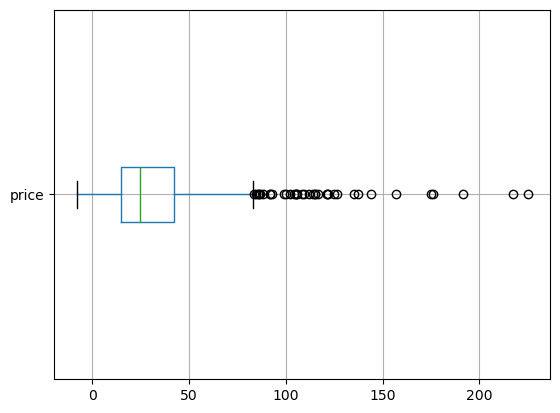

In [47]:
# Affichage d'un box plot afin de voir la dispersion des prix de vin
erp.boxplot(column="price", vert=False)
plt.show()

Le Z-score est une façon de comparer les scores entre eux et de voir qui se démarque de la moyenne, que ce soit vers le haut ou vers le bas. Ici, nous allons considérer le seuil de la comparaison est égal à 2. Si la valeur absolue du Z-score d'un produit est supérieure ou égale à 2, donc c'est un outlier.

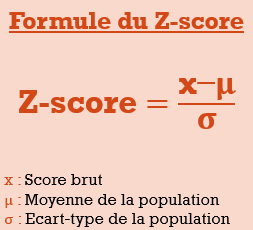

In [48]:
# Analyse statistique en utilisant le Z-score pour détecter les outliers
# Calcul du Z-score
df_final['z_score_price'] = (df_final['price'] - df_final['price'].mean()) / df_final['price'].std()

# Définition seuil
seuil = 2
outliers = df_final[df_final['z_score_price'].abs() >= seuil]

In [49]:
# Affichage du nombre de valeurs aberrantes
print("Il y a {} valeurs aberrantes parmi les prix de vin".format(outliers.shape[0]))

Il y a 30 valeurs aberrantes parmi les prix de vin


In [50]:
# Triage du Z-score du plus grand au plus petit
outliers = outliers.sort_values("z_score_price", ascending=True)

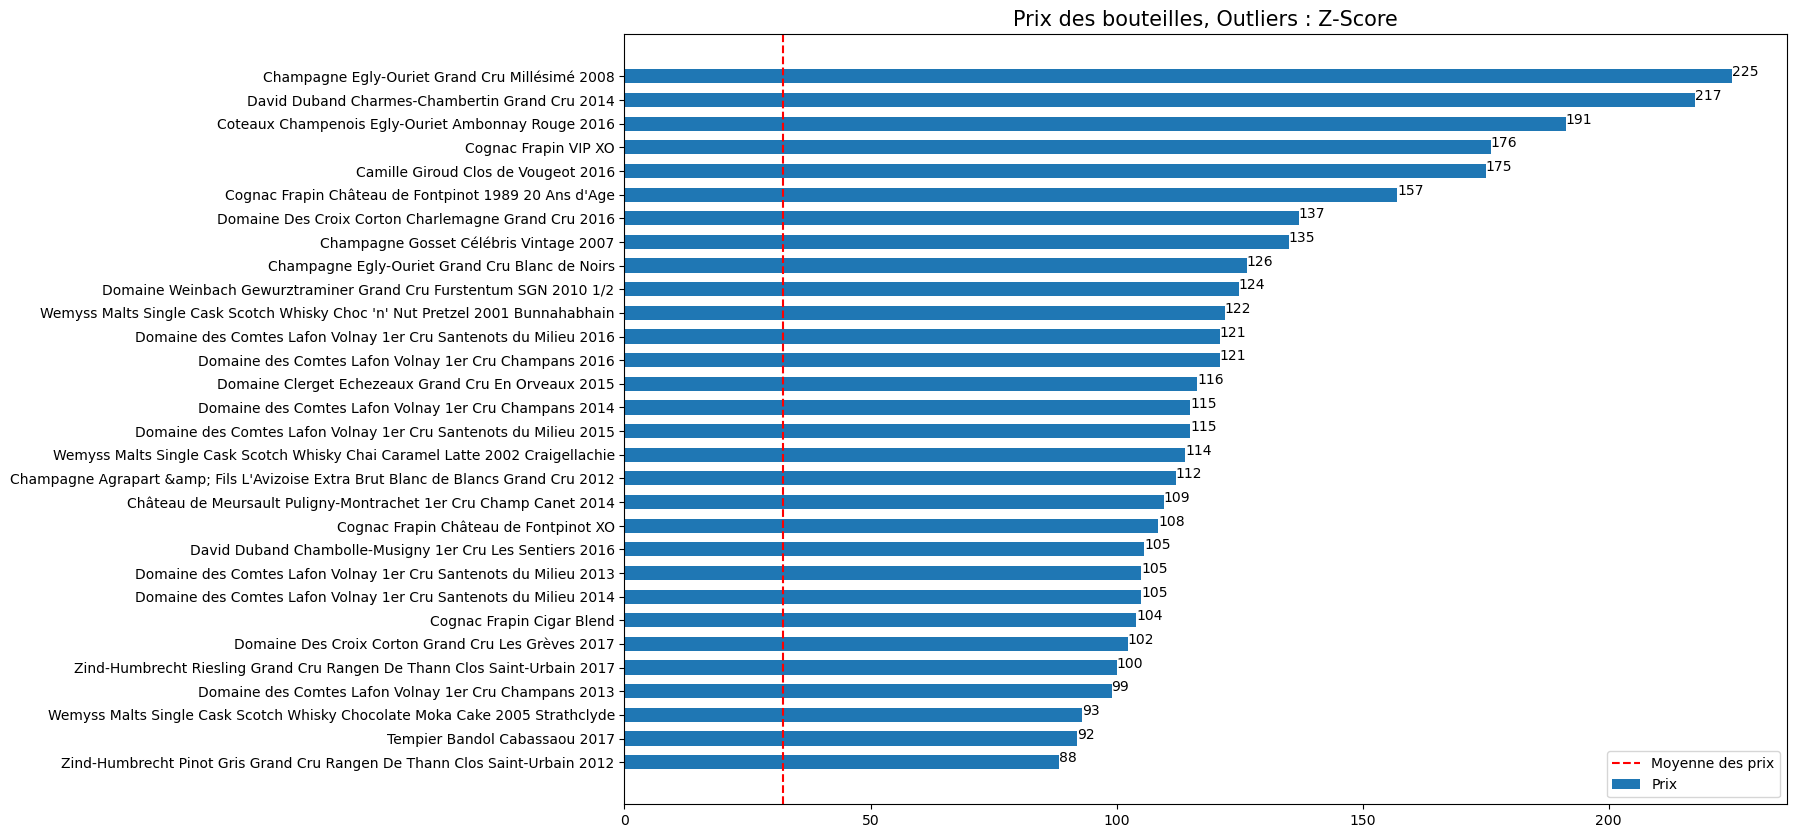

In [51]:
# Affichage des outliers ou valeurs aberrantes
plt.figure(figsize=(15,10))

plt.barh(outliers["post_title"], outliers["price"],height = 0.6, label="Prix")
plt.title("Prix des bouteilles, Outliers : Z-Score", fontsize=15)
plt.axvline(df_final["price"].mean(), color="r", linestyle="--", label="Moyenne des prix")

plt.legend()

for i, v in enumerate(outliers["price"]):
    plt.text(v, i, str(int(v)), color='black')

plt.show()

Vérification prix outlier vs prix réel sur internet :
Ce n'est pas vraiment un outlier mais il y a une différence de prix entre les gammes de produits 

<div style="background-color: RGB(0,150,250);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Recommandations</h2>
</div>

+ Assurer la cohérence entre stock_status et stock_quantity dans le système ERP (Responsable SI)
+ Vérification systématique du prix de chaque produit pour fiabiliser le suivi du chiffre d’affaires
+ Assurer la synchronisation entre les 2 systèmes ERP et Web pour optimiser la gestion de la boutique et faciliter le rapprochement entre eux.
    - &rarr; Automatiser le nettoyage des données afin de gagner du temps
+ Créer une base de données dédiée pour l’analyse des chiffres d’affaires par produit. Séparer les bases de données selon le « post_type » (product/attachment) afin d’éviter les doublons
